# Weather Time-Series EDA — Banha, Qalyubia, Egypt

**Task:** Weather Forecast API & Time-Series Exploratory Data Analysis  
**Source:** NASA POWER Daily Point API  
**Location:** Banha, Qalyubia, Egypt (approximate coordinates 30.46°N, 31.18°E)  
**Period:** 1 January 2025 – 31 December 2025  
**Frequency:** Daily

Run all cells from top to bottom with an internet connection. The notebook collects and preserves the raw API response, prepares a transparent daily table, runs quality checks, produces EDA plots, performs stationarity tests, and writes a short report. A single year is useful for an initial seasonal overview but limits robust annual decomposition and annual-cycle claims.

## 1. Install / import libraries

If a library is missing, uncomment and run the installation command below.

In [1]:
# If needed, install dependencies in a separate cell:
# %pip install -r requirements.txt

import json
import warnings
import platform
from pathlib import Path

import requests
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import statsmodels

from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.stats import zscore
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = PROJECT_DIR / "figures"
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

# Reproducibility: record runtime and library versions.
versions = {
    "Python": platform.python_version(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "scipy": scipy.__version__,
    "statsmodels": statsmodels.__version__,
    "requests": requests.__version__,
}
display(pd.Series(versions, name="version").to_frame())
print("Project directory:", PROJECT_DIR.resolve())

,version
Python,3.14.6
pandas,3.0.3
numpy,2.4.6
matplotlib,3.11.0
seaborn,0.13.2
scipy,1.18.0
statsmodels,0.14.6
requests,2.34.2


Project directory: C:\Users\noura\Weather_Time_Series_EDA\Weather_Time_Series_Task5_2020_onward


## 2. Collect data from NASA POWER API

The requested variables are mean, maximum and minimum air temperature at 2 m, and corrected precipitation. NASA POWER may use fill values for unavailable observations; these are checked below.

In [2]:
# API documentation for the submission
# Provider: NASA POWER Daily Point API
# Endpoint: https://power.larc.nasa.gov/api/temporal/daily/point
# Parameters: T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,WS2M
# Location: approximate Banha coordinates (latitude=30.46, longitude=31.18)
# Date range: 2025-01-01 through 2025-12-31
# Community: RE; response format: JSON
# Rate limits: no rate-limit response was observed during this single request.
# This is not a claim that the provider has no rate limits; consult NASA POWER
# documentation before running repeated or automated requests.
API_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"

params = {
    "parameters": "T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,WS2M",
    "community": "RE",
    "longitude": 31.18,
    "latitude": 30.46,
    "start": "20250101",
    "end": "20251231",
    "format": "JSON",
}

response = requests.get(API_URL, params=params, timeout=120)
print("HTTP status:", response.status_code)
response.raise_for_status()
raw_data = response.json()

raw_path = OUTPUT_DIR / "raw_weather_data.json"
with raw_path.open("w", encoding="utf-8") as f:
    json.dump(raw_data, f, ensure_ascii=False, indent=2)

print("Returned parameters:",
    list(raw_data["properties"]["parameter"].keys()))

print("Request URL and parameters are documented in this cell; "
    "no rate-limit response was observed for this single request.")

HTTP status: 200
Returned parameters: ['T2M', 'T2M_MAX', 'T2M_MIN', 'PRECTOTCORR', 'RH2M', 'WS2M']
Request URL and parameters are documented in this cell; no rate-limit response was observed for this single request.


## 3. Convert response to a DataFrame

Temperature is in degrees Celsius and precipitation is in millimetres per day, according to the API metadata. The original JSON is preserved separately.

In [3]:
parameters = raw_data["properties"]["parameter"]
df = pd.DataFrame(parameters)
df.index = pd.to_datetime(df.index, format="%Y%m%d", errors="coerce")
df.index.name = "date"
df = df.sort_index()

df = df.rename(columns={
    "T2M": "temperature",
    "T2M_MAX": "temperature_max",
    "T2M_MIN": "temperature_min",
    "PRECTOTCORR": "precipitation",
    "RH2M": "relative_humidity",
    "WS2M": "wind_speed",
})

# Keep core and optional columns when returned by the API.
ordered_columns = ["temperature", "temperature_max", "temperature_min", "precipitation",
                   "relative_humidity", "wind_speed"]
df = df[[c for c in ordered_columns if c in df.columns]].apply(pd.to_numeric, errors="coerce")
df = df.replace([-999, -999.0], np.nan)

print("Dataset shape:", df.shape)
print("Date range:", df.index.min(), "to", df.index.max())
display(df.head())

Dataset shape: (365, 6)
Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00


,temperature,temperature_max,temperature_min,precipitation,relative_humidity,wind_speed
date,,,,,,
2025-01-01,14.35,21.41,9.00,0.01,69.97,1.95
2025-01-02,13.49,20.84,8.36,0.03,75.26,2.46
2025-01-03,13.95,21.65,7.93,0.02,70.84,2.46
2025-01-04,14.13,21.57,8.51,0.00,53.21,2.39
2025-01-05,14.99,20.79,11.21,0.02,52.44,2.77


## 4. Data-quality checks

Check duplicate timestamps, missing dates, missing values, units, and physically suspicious values. Do not silently drop missing dates or observations.

In [4]:
expected_index = pd.date_range("2025-01-01", "2025-12-31", freq="D")
missing_dates = expected_index.difference(df.index)
duplicate_count = int(df.index.duplicated().sum())
missing_by_column = df.isna().sum()

print("Expected daily records:", len(expected_index))
print("Actual records:", len(df))
print("Duplicate timestamps:", duplicate_count)
print("Missing dates:", len(missing_dates))
print("Missing values per column:")
display(missing_by_column.to_frame("missing_count"))

# Unit map based on NASA POWER parameter metadata.
unit_map = {
    "temperature": "°C", "temperature_max": "°C", "temperature_min": "°C",
    "precipitation": "mm/day", "relative_humidity": "%",
    "wind_speed": "m/s (verify metadata)"
}
quality_table = pd.DataFrame({
    "non_missing_count": df.count(),
    "missing_count": df.isna().sum(),
    "minimum": df.min(numeric_only=True),
    "maximum": df.max(numeric_only=True),
    "unit": pd.Series({c: unit_map.get(c, "check API metadata") for c in df.columns})
})
display(quality_table)
quality_table.to_csv(OUTPUT_DIR / "data_quality_table.csv", index_label="variable")

print("\nAPI parameter metadata:")
display(pd.DataFrame(raw_data.get("parameters", {})).T if isinstance(raw_data.get("parameters"), dict) else raw_data.get("parameters"))

quality_flags = pd.DataFrame(index=df.index)
quality_flags["negative_precipitation"] = df["precipitation"] < 0
quality_flags["max_below_min"] = df["temperature_max"] < df["temperature_min"]
quality_flags["mean_outside_min_max"] = (
    (df["temperature"] < df["temperature_min"]) |
    (df["temperature"] > df["temperature_max"])
)
print("\nSuspicious-value counts:")
display(quality_flags.sum().to_frame("flag_count"))

Expected daily records: 365
Actual records: 365
Duplicate timestamps: 0
Missing dates: 0
Missing values per column:


,missing_count
temperature,0
temperature_max,0
temperature_min,0
precipitation,0
relative_humidity,0
wind_speed,0


,non_missing_count,missing_count,minimum,maximum,unit
temperature,365,0,10.11,34.45,°C
temperature_max,365,0,16.19,44.75,°C
temperature_min,365,0,3.69,26.83,°C
precipitation,365,0,0.00,4.49,mm/day
relative_humidity,365,0,19.80,77.57,%
wind_speed,365,0,0.61,5.34,m/s (verify metadata)



API parameter metadata:


,units,longname
T2M,C,Temperature at 2 Meters
T2M_MAX,C,Temperature at 2 Meters Maximum
T2M_MIN,C,Temperature at 2 Meters Minimum
PRECTOTCORR,mm/day,Precipitation Corrected
RH2M,%,Relative Humidity at 2 Meters
WS2M,m/s,Wind Speed at 2 Meters



Suspicious-value counts:


,flag_count
negative_precipitation,0
max_below_min,0
mean_outside_min_max,0


## 5. Missing-value strategy and cleaned dataset

Missing dates are reindexed to the expected daily calendar. Missing observations are reported and retained as missing in the main cleaned dataset, rather than being silently fabricated. Interpolation is created only as a separate analysis series where a statistical method requires a complete series.

In [5]:
df = df.reindex(expected_index)
df.index.name = "date"

# Save the cleaned table with missing values preserved for transparent data-quality reporting.
clean_csv_path = OUTPUT_DIR / "weather_data.csv"
df.to_csv(clean_csv_path, index_label="date")
print("Cleaned CSV saved:", clean_csv_path.resolve())

# Interpolate only short gaps for selected time-series methods; keep original df unchanged.
analysis_df = df.interpolate(method="time", limit=3, limit_area="inside")
print("Missing values after limited interpolation (analysis copy):")
display(analysis_df.isna().sum().to_frame("remaining_missing"))

Cleaned CSV saved: C:\Users\noura\Weather_Time_Series_EDA\Weather_Time_Series_Task5_2020_onward\outputs\weather_data.csv
Missing values after limited interpolation (analysis copy):


,remaining_missing
temperature,0
temperature_max,0
temperature_min,0
precipitation,0
relative_humidity,0
wind_speed,0


## 6. Descriptive statistics and distributions

,count,mean,std,min,25%,50%,75%,max
temperature,365.0,23.197726,6.269831,10.11,16.51,23.83,28.86,34.45
temperature_max,365.0,31.687233,7.280679,16.19,24.16,32.80,38.29,44.75
temperature_min,365.0,16.189068,5.288393,3.69,11.14,16.91,20.53,26.83
precipitation,365.0,0.109068,0.472706,0.00,0.00,0.00,0.01,4.49
relative_humidity,365.0,52.962959,10.487493,19.80,46.38,52.44,59.89,77.57
wind_speed,365.0,2.592055,0.724329,0.61,2.13,2.59,3.07,5.34


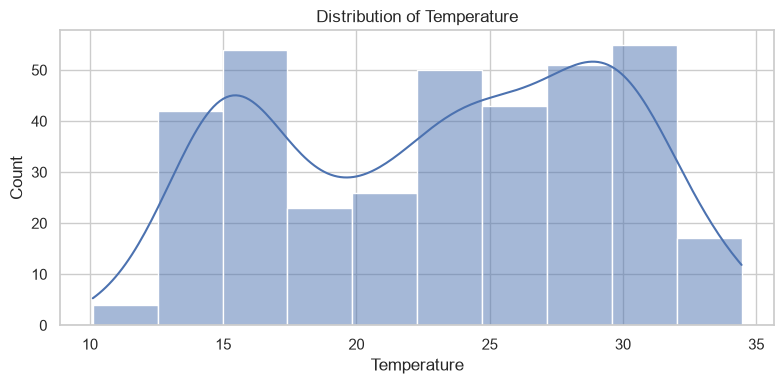

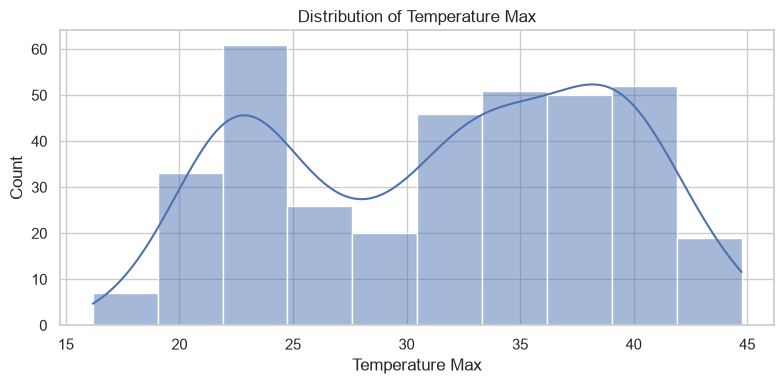

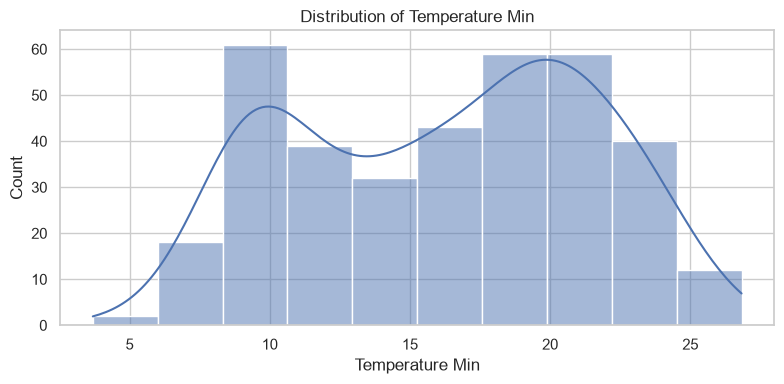

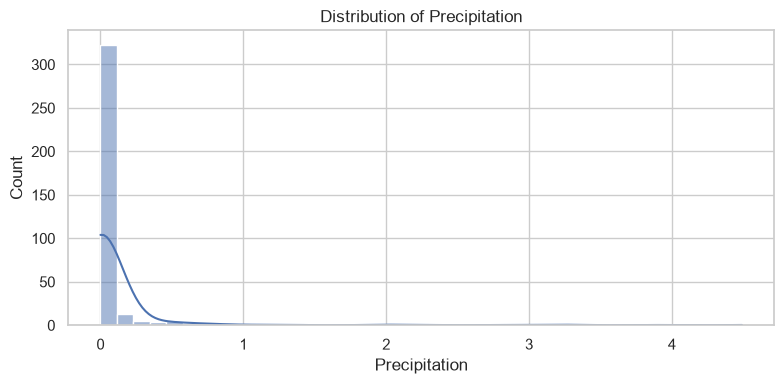

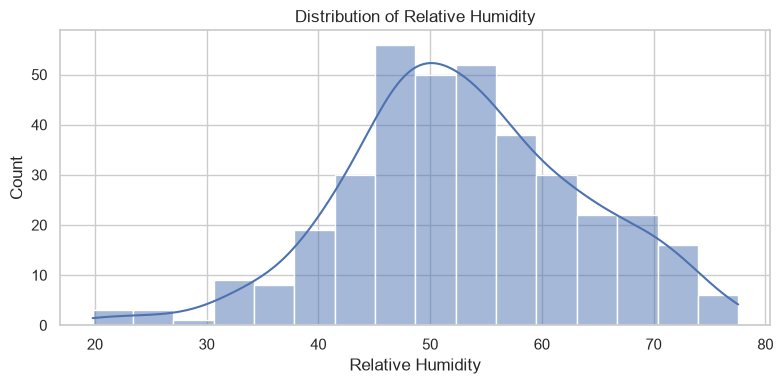

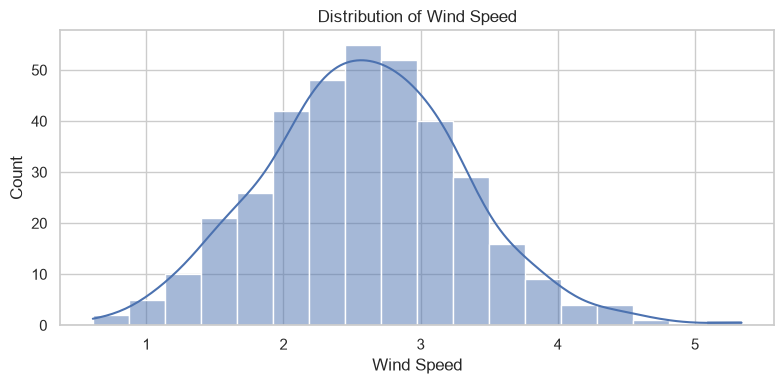

In [6]:
display(df.describe().T)

for col in df.columns:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(f"Distribution of {col.replace('_', ' ').title()}")
    ax.set_xlabel(col.replace("_", " ").title())
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / f"distribution_{col}.png", dpi=150)
    plt.show()

## 7. Time-series plots and rolling statistics

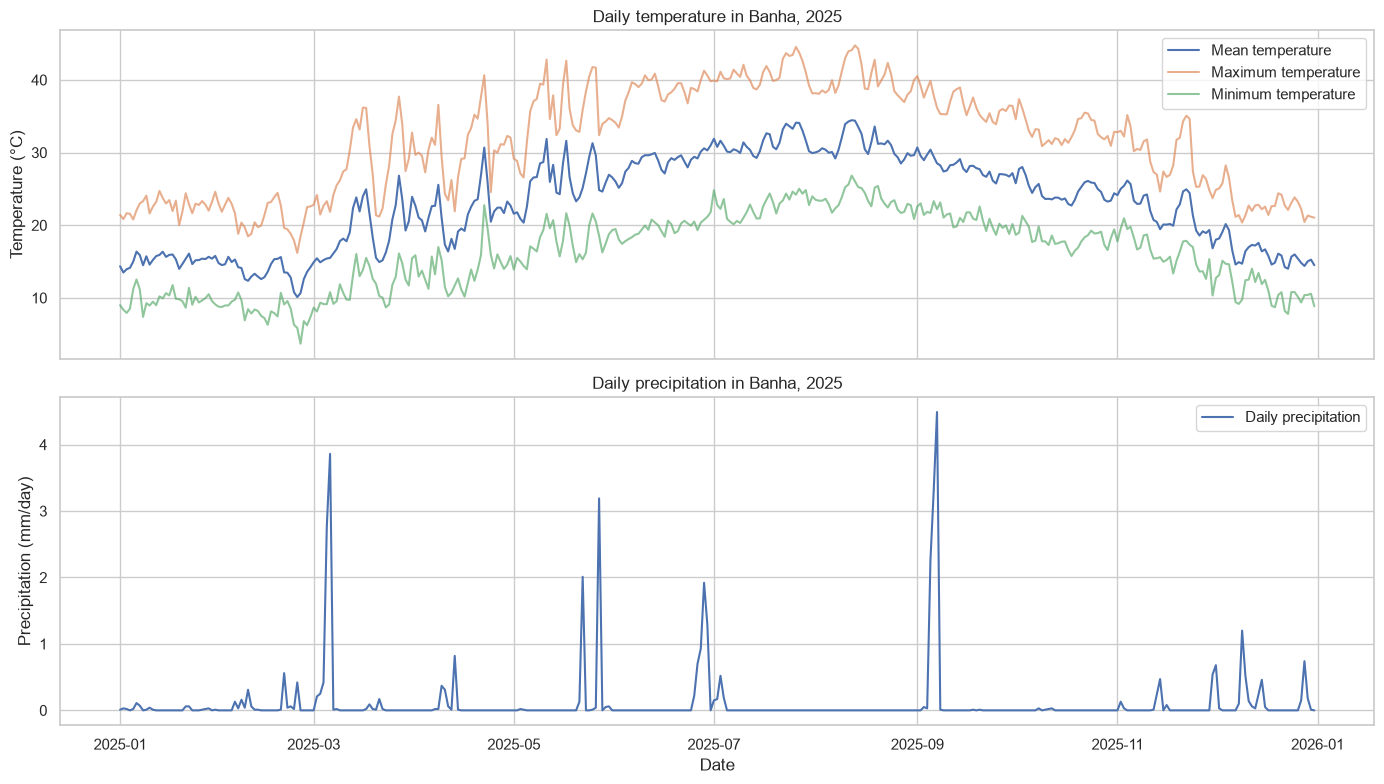

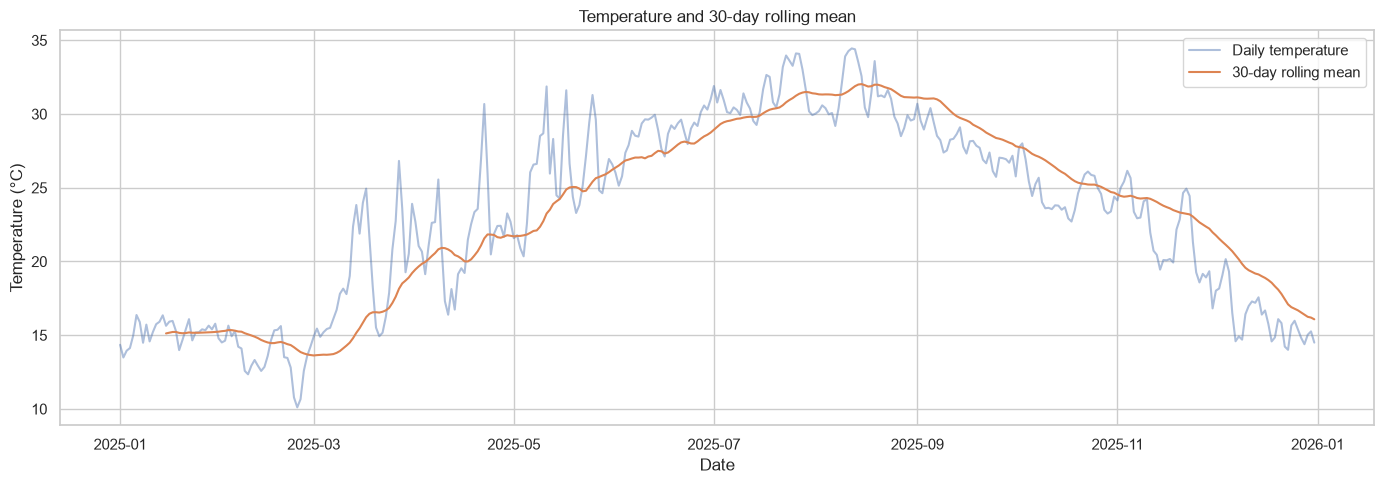

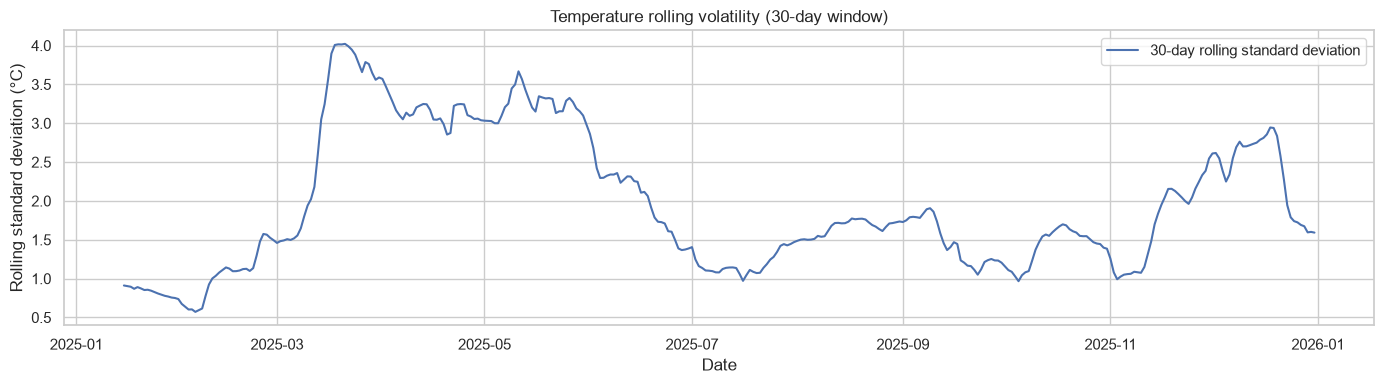

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(df.index, df["temperature"], label="Mean temperature")
axes[0].plot(df.index, df["temperature_max"], alpha=0.65, label="Maximum temperature")
axes[0].plot(df.index, df["temperature_min"], alpha=0.65, label="Minimum temperature")
axes[0].set_ylabel("Temperature (°C)")
axes[0].set_title("Daily temperature in Banha, 2025")
axes[0].legend()

axes[1].plot(df.index, df["precipitation"], label="Daily precipitation")
axes[1].set_ylabel("Precipitation (mm/day)")
axes[1].set_xlabel("Date")
axes[1].set_title("Daily precipitation in Banha, 2025")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "temperature_and_precipitation.png", dpi=150)
plt.show()

rolling_mean = df["temperature"].rolling(30, min_periods=15).mean()
rolling_std = df["temperature"].rolling(30, min_periods=15).std()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["temperature"], alpha=0.45, label="Daily temperature")
ax.plot(df.index, rolling_mean, label="30-day rolling mean")
ax.set_title("Temperature and 30-day rolling mean")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "temperature_rolling_mean.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, rolling_std, label="30-day rolling standard deviation")
ax.set_title("Temperature rolling volatility (30-day window)")
ax.set_xlabel("Date")
ax.set_ylabel("Rolling standard deviation (°C)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "temperature_rolling_std.png", dpi=150)
plt.show()

## 8. Monthly seasonality

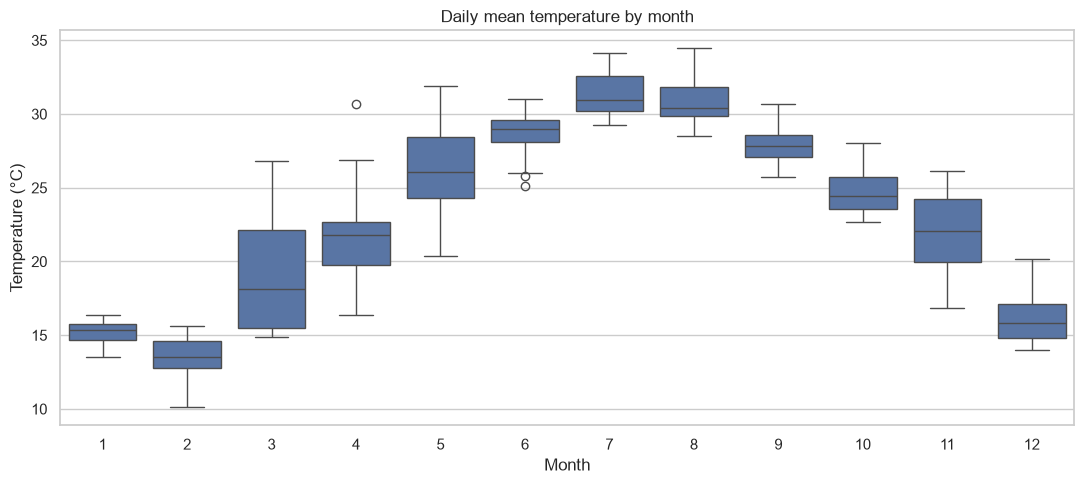

temperature               precipitation       
            mean    min    max          mean    sum
date                                               
1      15.210968  13.49  16.37      0.016452   0.51
2      13.540714  10.11  15.65      0.066429   1.86
3      19.075806  14.89  26.82      0.253548   7.86
4      21.741333  16.39  30.68      0.054000   1.62
5      26.073548  20.35  31.87      0.178065   5.52
6      28.742000  25.14  30.99      0.168667   5.06
7      31.423226  29.26  34.11      0.033226   1.03
8      31.079355  28.50  34.45      0.000000   0.00
9      27.980667  25.74  30.70      0.339000  10.17
10     24.699032  22.71  28.01      0.002903   0.09
11     21.976667  16.82  26.15      0.050000   1.50
12     16.141613  14.01  20.16      0.148065   4.59

In [8]:
monthly = df.assign(month=df.index.month)
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=monthly, x="month", y="temperature", ax=ax)
ax.set_title("Daily mean temperature by month")
ax.set_xlabel("Month")
ax.set_ylabel("Temperature (°C)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "temperature_by_month.png", dpi=150)
plt.show()

monthly_summary = df.groupby(df.index.month).agg({
    "temperature": ["mean", "min", "max"],
    "precipitation": ["mean", "sum"]
})
display(monthly_summary)

## 9. Decomposition

A daily series with one year of data may not support a robust estimate of annual seasonality (period=365) because only one complete annual cycle is available. Therefore, the notebook uses a 7-day period to inspect weekly structure, and interprets it cautiously. A 365-day decomposition would require multiple years for a more defensible annual seasonal estimate.

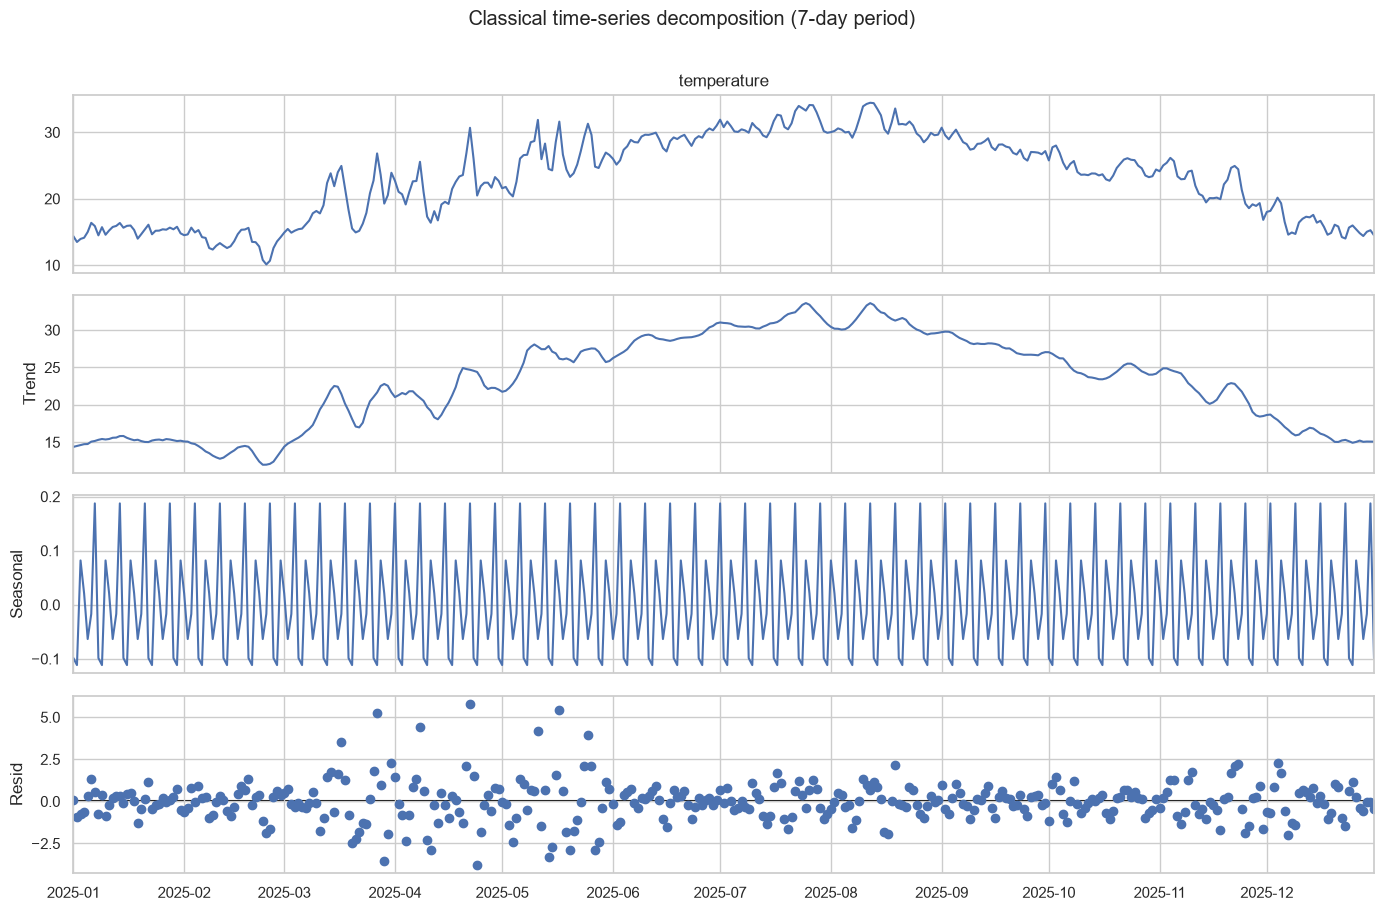

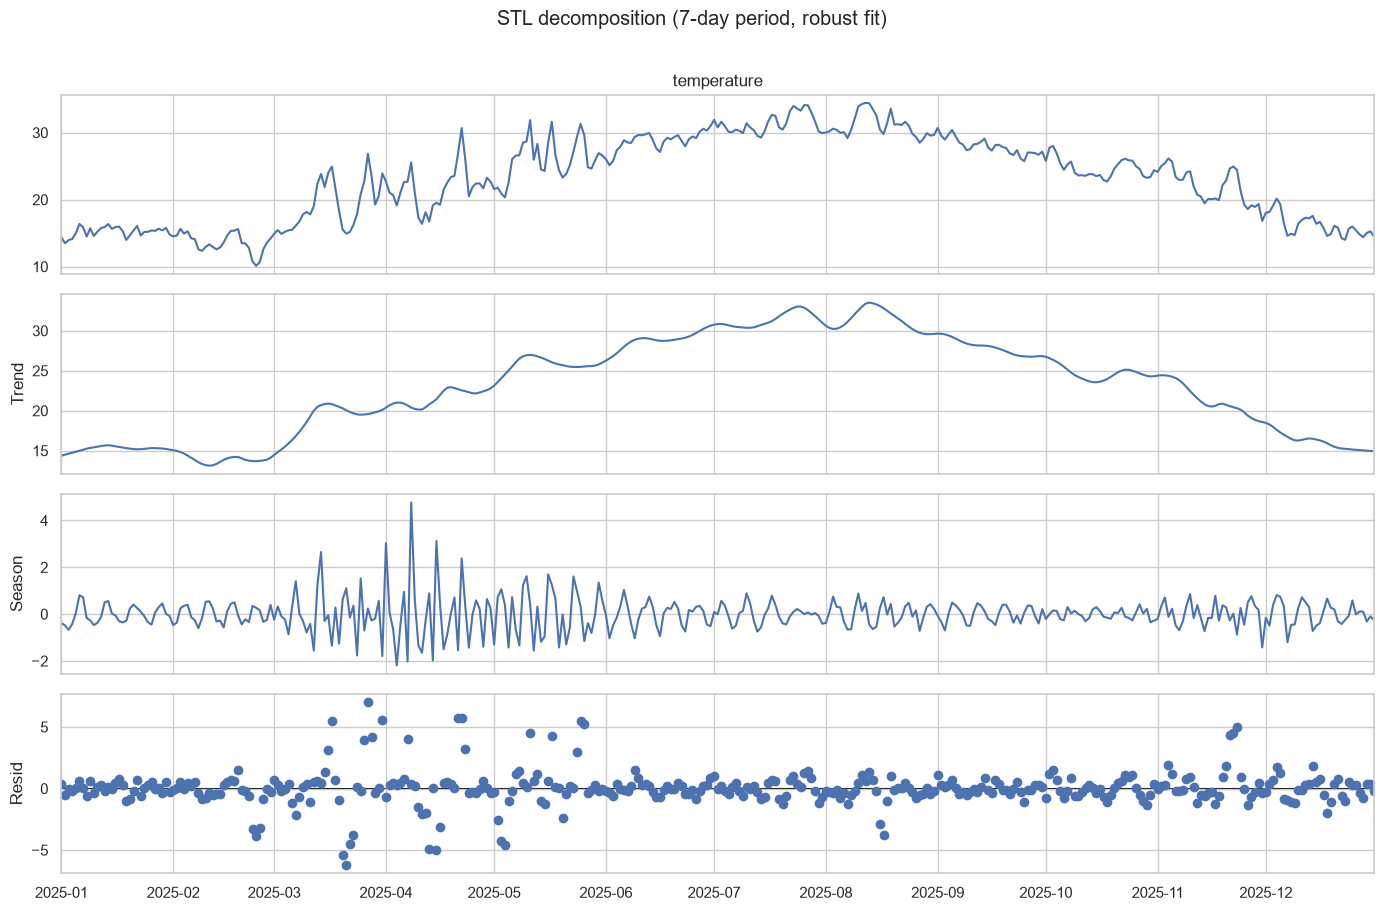

In [9]:
series = analysis_df["temperature"].dropna()
if len(series) >= 21:
    # Classical decomposition with weekly period; annual seasonal estimation is weak with one year only.
    decomp = seasonal_decompose(series, model="additive", period=7, extrapolate_trend="freq")
    fig = decomp.plot()
    fig.set_size_inches(14, 9)
    fig.suptitle("Classical time-series decomposition (7-day period)", y=1.01)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "temperature_decomposition_period7.png", dpi=150)
    plt.show()

    # STL is more flexible and robust to outliers when robust=True.
    stl_result = STL(series, period=7, robust=True).fit()
    fig = stl_result.plot()
    fig.set_size_inches(14, 9)
    fig.suptitle("STL decomposition (7-day period, robust fit)", y=1.01)
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / "temperature_stl_period7.png", dpi=150)
    plt.show()
else:
    print("Not enough complete temperature observations for decomposition.")

## 10. ACF and PACF

ACF/PACF are calculated on the available temperature analysis series. They help inspect lag dependence, but visible peaks alone do not prove a causal relationship. With only one year of daily observations, do not claim a reliable annual ACF cycle from the plot alone; longer multi-year data would be better for confirming annual periodicity.

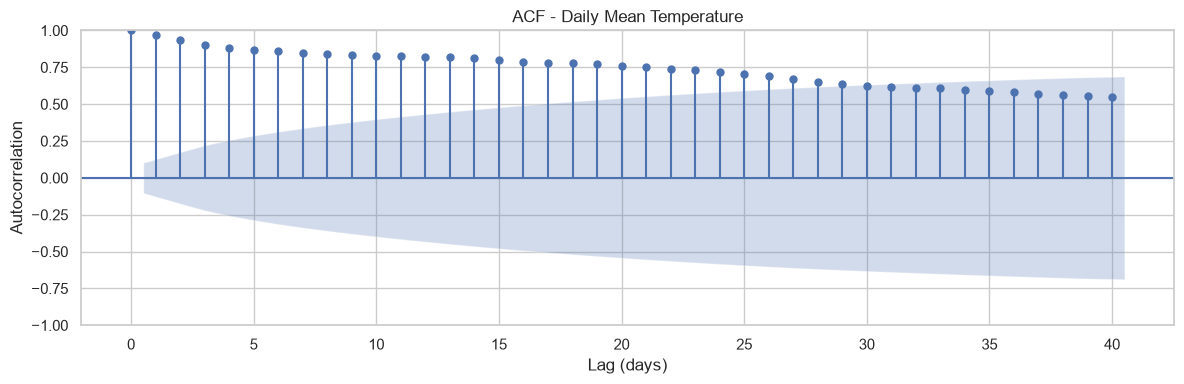

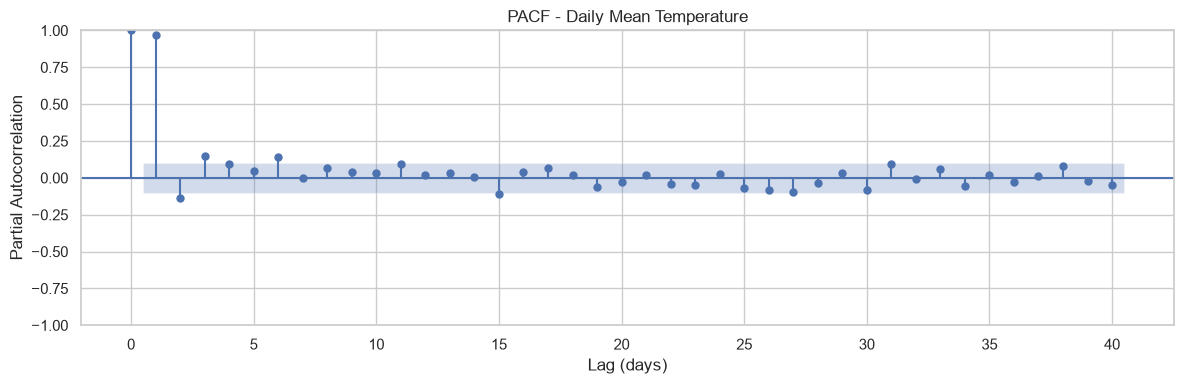

In [10]:
series = analysis_df["temperature"].dropna()
if len(series) > 30:
    # ACF plot
    fig, ax = plt.subplots(figsize=(12, 4))

    plot_acf(
        series,
        lags=min(40, len(series) // 2 - 1),
        ax=ax
    )

    ax.set_title("ACF - Daily Mean Temperature")
    ax.set_xlabel("Lag (days)")
    ax.set_ylabel("Autocorrelation")

    fig.tight_layout()
    fig.savefig(
        FIGURE_DIR / "temperature_acf.png",
        dpi=150
    )
    plt.show()

    # PACF plot
    fig, ax = plt.subplots(figsize=(12, 4))

    plot_pacf(
        series,
        lags=min(40, len(series) // 2 - 1),
        method="ywm",
        ax=ax
    )

    ax.set_title("PACF - Daily Mean Temperature")
    ax.set_xlabel("Lag (days)")
    ax.set_ylabel("Partial Autocorrelation")

    fig.tight_layout()
    fig.savefig(
        FIGURE_DIR / "temperature_pacf.png",
        dpi=150
    )
    plt.show()

else:
    print("Not enough observations for ACF/PACF.")


## 11. Stationarity test (Augmented Dickey-Fuller)

The ADF null hypothesis is that the series has a unit root (is non-stationary). A p-value below 0.05 is commonly treated as evidence against the null hypothesis. Interpret this alongside plots and seasonal behaviour.

In [11]:
adf_series = analysis_df["temperature"].dropna()

def run_stationarity_tests(series, label):
    print(f"\\n--- {label} ---")
    if len(series) < 20:
        print("Not enough observations.")
        return None
    adf_res = adfuller(series, autolag="AIC")
    print(f"ADF statistic: {adf_res[0]:.4f}; p-value: {adf_res[1]:.6f}")
    try:
        kpss_res = kpss(series, regression="c", nlags="auto")
        print(f"KPSS statistic: {kpss_res[0]:.4f}; p-value: {kpss_res[1]:.6f}")
        print("ADF H0: unit root / non-stationarity. KPSS H0: level stationarity.")
        if adf_res[1] >= 0.05 and kpss_res[1] < 0.05:
            print("Combined interpretation: both tests support treating the series as non-stationary.")
        elif adf_res[1] < 0.05 and kpss_res[1] >= 0.05:
            print("Combined interpretation: both tests are consistent with stationarity.")
        else:
            print("Combined interpretation: tests are mixed or inconclusive; inspect trend/seasonality.")
    except Exception as exc:
        print("KPSS could not be computed:", exc)
    return adf_res

original_adf = run_stationarity_tests(adf_series, "Original daily mean temperature")

# First difference as a simple diagnostic transformation, not a guarantee of model suitability.
diff_series = adf_series.diff().dropna()
differenced_adf = run_stationarity_tests(diff_series, "First-differenced daily mean temperature")

\n--- Original daily mean temperature ---
ADF statistic: -0.9746; p-value: 0.762432
KPSS statistic: 1.0553; p-value: 0.010000
ADF H0: unit root / non-stationarity. KPSS H0: level stationarity.
Combined interpretation: both tests support treating the series as non-stationary.
\n--- First-differenced daily mean temperature ---
ADF statistic: -8.8670; p-value: 0.000000
KPSS statistic: 0.4624; p-value: 0.050252
ADF H0: unit root / non-stationarity. KPSS H0: level stationarity.
Combined interpretation: both tests are consistent with stationarity.


## 12. Correlation and outlier review

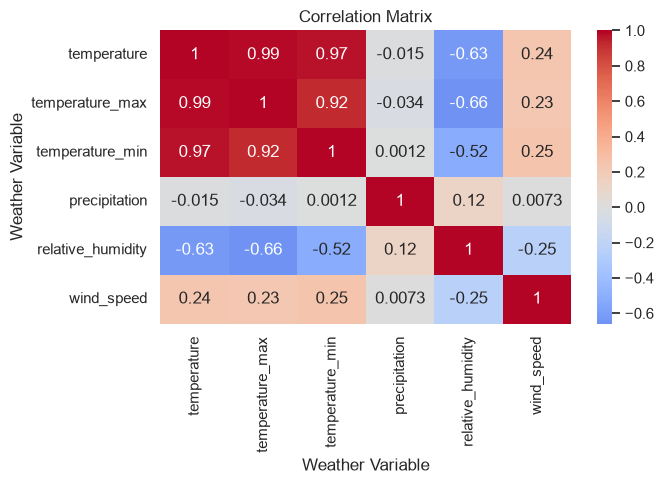

IQR outlier flags (review, not automatic errors):


,flagged_count
temperature,0
temperature_max,0
temperature_min,0
precipitation,70
relative_humidity,4
wind_speed,4


Physically suspicious values are listed separately in the data-quality checks above.


In [12]:

# Correlation matrix
fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    center=0,
    ax=ax
)

ax.set_title("Correlation Matrix")
ax.set_xlabel("Weather Variable")
ax.set_ylabel("Weather Variable")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "correlation_matrix.png", dpi=150)
plt.show()


# IQR outlier flags for each variable
outlier_summary = {}

for col in df.select_dtypes(include=np.number).columns:
    values = df[col].dropna()

    if len(values) > 0:
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        mask = (
            (df[col] < q1 - 1.5 * iqr)
            | (df[col] > q3 + 1.5 * iqr)
        )

        outlier_summary[col] = int(mask.sum())

print("IQR outlier flags (review, not automatic errors):")

display(
    pd.Series(
        outlier_summary,
        name="flagged_count"
    ).to_frame()
)

print(
    "Physically suspicious values are listed "
    "separately in the data-quality checks above."
)


## 13. Additional time-series diagnostics

This section adds rolling-window outlier flags, diurnal temperature range, precipitation concentration, wet-day counts, log-scale precipitation distribution, lagged correlations, and an optional external comparison. These analyses complement rather than replace the required EDA.

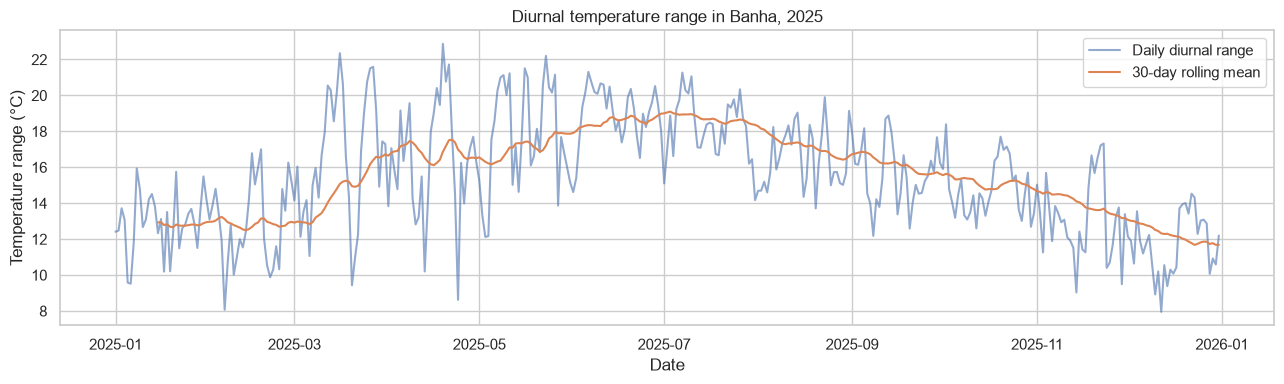

In [13]:
# Diurnal temperature range (DTR = daily maximum - daily minimum).
df["diurnal_range"] = df["temperature_max"] - df["temperature_min"]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(df.index, df["diurnal_range"], alpha=0.6, label="Daily diurnal range")
ax.plot(df["diurnal_range"].rolling(30, min_periods=15).mean(), label="30-day rolling mean")
ax.set_title("Diurnal temperature range in Banha, 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature range (°C)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "diurnal_temperature_range.png", dpi=150)
plt.show()

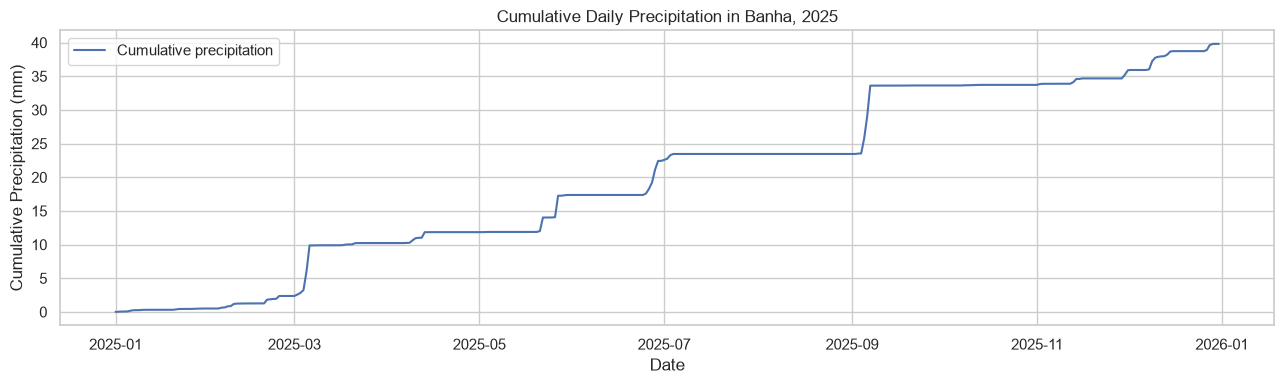

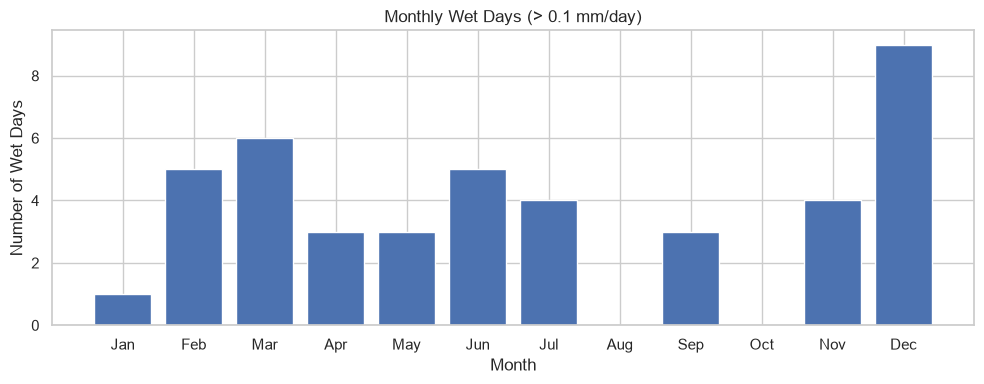

Wet days (> 0.1 mm): 43 of 365
Days with measurable precipitation (> 0 mm): 102
Maximum daily precipitation: 4.49 mm on 2025-09-07


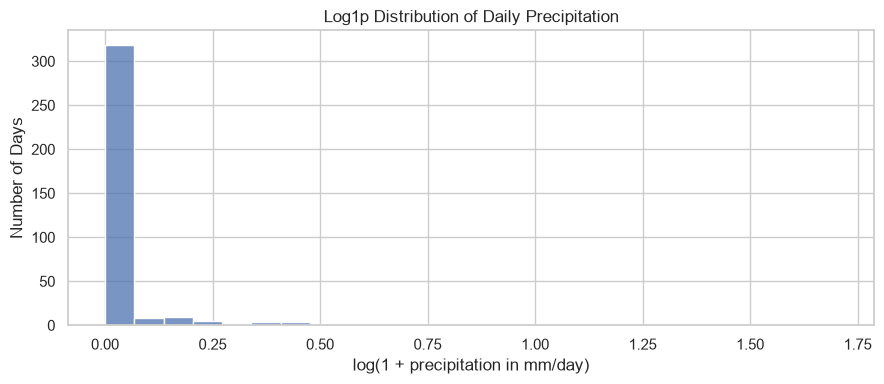

In [14]:

# Precipitation concentration and wet-day analysis

rain = df["precipitation"].clip(lower=0)

# 1. Cumulative precipitation
fig, ax = plt.subplots(figsize=(13, 4))

ax.plot(
    rain.index,
    rain.cumsum(),
    label="Cumulative precipitation"
)

ax.set_title("Cumulative Daily Precipitation in Banha, 2025")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative Precipitation (mm)")
ax.legend()

fig.tight_layout()
fig.savefig(FIGURE_DIR / "cumulative_precipitation.png", dpi=150)
plt.show()


# 2. Monthly wet days (> 0.1 mm)
wet_day_threshold = 0.1

wet_days = (
    (rain > wet_day_threshold)
    .groupby(rain.index.month)
    .sum()
    .reindex(range(1, 13), fill_value=0)
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(month_names, wet_days.values)

ax.set_title("Monthly Wet Days (> 0.1 mm/day)")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Wet Days")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "monthly_wet_days.png", dpi=150)
plt.show()


# 3. Rainfall summary
print(
    "Wet days (> 0.1 mm):",
    int((rain > wet_day_threshold).sum()),
    "of",
    len(rain)
)

print(
    "Days with measurable precipitation (> 0 mm):",
    int((rain > 0).sum())
)

if rain.notna().any():
    max_rain_date = rain.idxmax()

    print(
        "Maximum daily precipitation:",
        round(float(rain.max()), 2),
        "mm on",
        max_rain_date.strftime("%Y-%m-%d")
    )


# 4. Log1p precipitation distribution
fig, ax = plt.subplots(figsize=(9, 4))

sns.histplot(
    np.log1p(rain.dropna()),
    bins=25,
    kde=False,
    ax=ax
)

ax.set_title("Log1p Distribution of Daily Precipitation")
ax.set_xlabel("log(1 + precipitation in mm/day)")
ax.set_ylabel("Number of Days")

fig.tight_layout()
fig.savefig(FIGURE_DIR / "precipitation_log_histogram.png", dpi=150)
plt.show()


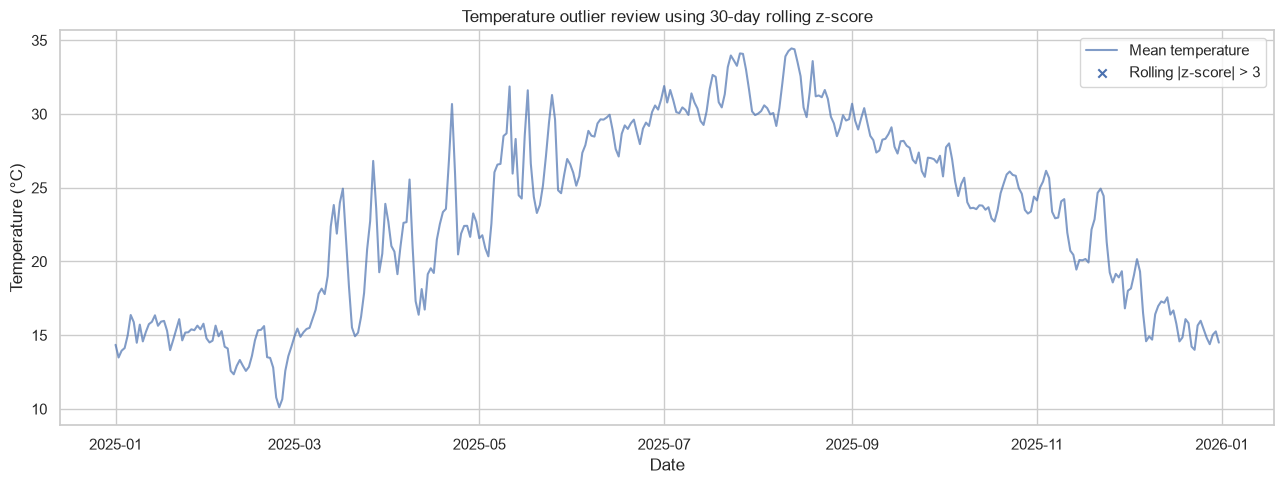

Rolling-window temperature outlier flags: 0


,precipitation_lag_days,correlation
0,-7,-0.022795
1,-6,-0.007617
2,-5,0.009039
3,-4,0.006198
4,-3,0.001603
5,-2,0.007011
6,-1,0.004627
7,0,-0.015416
8,1,-0.013003
9,2,-0.004097


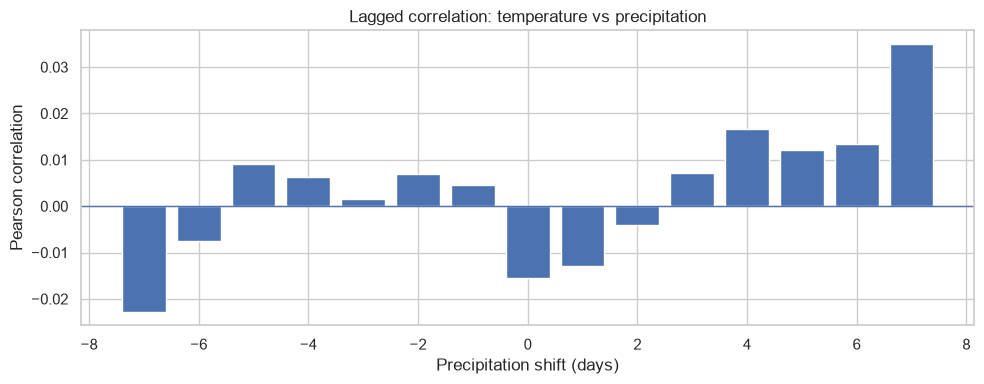

In [15]:
# Rolling-window outliers: a 30-day rolling z-score to account for changing seasonal baselines.
temp = df["temperature"]
rolling_mu = temp.rolling(30, center=True, min_periods=15).mean()
rolling_sigma = temp.rolling(30, center=True, min_periods=15).std()
rolling_z = (temp - rolling_mu) / rolling_sigma.replace(0, np.nan)
rolling_outliers = rolling_z.abs() > 3

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(temp.index, temp, label="Mean temperature", alpha=0.7)
ax.scatter(temp.index[rolling_outliers.fillna(False)],
           temp[rolling_outliers.fillna(False)],
           label="Rolling |z-score| > 3", marker="x")
ax.set_title("Temperature outlier review using 30-day rolling z-score")
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "rolling_temperature_outliers.png", dpi=150)
plt.show()
print("Rolling-window temperature outlier flags:", int(rolling_outliers.sum()))

# Correlation at lag 0 and lags +/- 1..7 days. Correlation is descriptive, not causal.
temp_precip = pd.concat([df["temperature"], df["precipitation"]], axis=1).dropna()
lag_rows = []
for lag in range(-7, 8):
    corr = df["temperature"].corr(df["precipitation"].shift(lag))
    lag_rows.append({"precipitation_lag_days": lag, "correlation": corr})
lag_corr = pd.DataFrame(lag_rows)
display(lag_corr)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(lag_corr["precipitation_lag_days"], lag_corr["correlation"])
ax.axhline(0, linewidth=1)
ax.set_title("Lagged correlation: temperature vs precipitation")
ax.set_xlabel("Precipitation shift (days)")
ax.set_ylabel("Pearson correlation")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "lagged_temperature_precipitation_correlation.png", dpi=150)
plt.show()

# Save additional diagnostic tables.
lag_corr.to_csv(OUTPUT_DIR / "lagged_correlation.csv", index=False)
pd.DataFrame({
    "temperature": df["temperature"],
    "rolling_z_score": rolling_z,
    "rolling_outlier_flag": rolling_outliers
}).to_csv(OUTPUT_DIR / "rolling_outlier_flags.csv", index_label="date")

## 14. Optional external validation with Open-Meteo

NASA POWER represents gridded/reanalysis-based data rather than a direct observation from a weather station at the exact coordinate. The optional cell below requests daily mean temperature and precipitation from Open-Meteo for a comparison. Differences are expected because products, spatial grids, and methods differ. Treat this as a broad cross-source comparison, not ground-truth validation. It requires internet access and can be skipped if unavailable.

In [16]:
try:
    om_url = "https://archive-api.open-meteo.com/v1/archive"
    om_params = {
        "latitude": 30.46,
        "longitude": 31.18,
        "start_date": "2025-01-01",
        "end_date": "2025-12-31",
        "daily": "temperature_2m_mean,precipitation_sum",
        "timezone": "Africa/Cairo",
    }
    om_response = requests.get(om_url, params=om_params, timeout=120)
    om_response.raise_for_status()
    om_data = om_response.json()["daily"]
    om_df = pd.DataFrame({
        "date": pd.to_datetime(om_data["time"]),
        "open_meteo_temperature": om_data["temperature_2m_mean"],
        "open_meteo_precipitation": om_data["precipitation_sum"],
    }).set_index("date")
    comparison = df.join(om_df, how="inner")
    comparison_summary = pd.Series({
        "temperature_mean_absolute_difference_C": (
            comparison["temperature"] - comparison["open_meteo_temperature"]
        ).abs().mean(),
        "precipitation_mean_absolute_difference_mm": (
            comparison["precipitation"] - comparison["open_meteo_precipitation"]
        ).abs().mean(),
        "matched_days": len(comparison),
    })
    display(comparison_summary.to_frame("value"))
    comparison.to_csv(OUTPUT_DIR / "nasa_power_vs_open_meteo_daily.csv", index_label="date")
except Exception as exc:
    print("Optional Open-Meteo comparison was skipped or failed:", repr(exc))
    print("This does not prevent the NASA POWER EDA from running.")

,value
temperature_mean_absolute_difference_C,0.567534
precipitation_mean_absolute_difference_mm,0.135260
matched_days,365.000000


## 13. Export a concise written summary

The summary is generated from the actual downloaded data and test result. Review the report before submission and ensure it accurately describes the outputs.

In [17]:
start_actual = df.index.min().date() if len(df) else "N/A"
end_actual = df.index.max().date() if len(df) else "N/A"
missing_total = int(df.isna().sum().sum())
duplicate_total = int(df.index.duplicated().sum())
n_records = len(df)

adf_stat = float(original_adf[0]) if original_adf is not None else np.nan
adf_pvalue = float(original_adf[1]) if original_adf is not None else np.nan
diff_adf_pvalue = float(differenced_adf[1]) if differenced_adf is not None else np.nan
adf_conclusion = (
    "The ADF test rejects the unit-root null at the 5% level."
    if adf_pvalue < 0.05 else
    "The ADF test does not reject the unit-root null at the 5% level; non-stationarity remains plausible."
)
monthly_means = df["temperature"].resample("MS").mean().dropna()
coldest_month = monthly_means.idxmin() if len(monthly_means) else None
warmest_month = monthly_means.idxmax() if len(monthly_means) else None
monthly_range_text = (
    f"Monthly mean temperature ranged from about {monthly_means.min():.1f} °C "
    f"({coldest_month.strftime('%B')}) to {monthly_means.max():.1f} °C "
    f"({warmest_month.strftime('%B')}), while daily means ranged from "
    f"{df['temperature'].min():.1f} to {df['temperature'].max():.1f} °C."
    if len(monthly_means) else "Monthly temperature summaries were unavailable."
)
rain = df["precipitation"].clip(lower=0)
wet_days_any = int((rain > 0).sum())
wet_days_01 = int((rain > 0.1).sum())
max_rain_date = rain.idxmax() if rain.notna().any() else None
max_rain_value = float(rain.max()) if rain.notna().any() else np.nan
temp_rain_corr = df["temperature"].corr(df["precipitation"])
api_params_text = "T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,WS2M"

report = f'''# Weather Time-Series EDA Summary

**Region:** Banha, Qalyubia, Egypt (approx. 30.46°N, 31.18°E)  
**Period:** {start_actual} to {end_actual}; {n_records} daily rows.  
**Source:** NASA POWER Daily Point API; temperature in °C, precipitation in mm/day.

## Main patterns
{monthly_range_text} There were {wet_days_any} days with precipitation above 0 mm and {wet_days_01} wet days above 0.1 mm. Maximum daily precipitation was {max_rain_value:.2f} mm on {max_rain_date.strftime('%d %B') if max_rain_date is not None else 'N/A'}. The contemporaneous temperature–precipitation correlation was {temp_rain_corr:.2f}, indicating little linear association at lag 0. Review the cumulative-rainfall plot and lagged correlations for event timing.

## Stationarity
ADF p-value: {adf_pvalue:.4f}; first-difference ADF p-value: {diff_adf_pvalue:.4f}. {adf_conclusion} Differencing may help; confirm the transformed series with both ADF and KPSS before modeling. A single year provides limited evidence for a robust annual seasonal component.

## Data quality and methods
The notebook checks gaps, duplicates, missing values, suspicious ranges, global IQR flags and 30-day rolling z-score outliers. Missing values are reported rather than silently dropped; short internal gaps are interpolated only in a separate analysis copy. STL and classical decomposition are included as exploratory diagnostics.

## Reproducibility and limitations
Endpoint: `https://power.larc.nasa.gov/api/temporal/daily/point`; parameters: `{api_params_text}`; dates: `20250101`–`20251231`; community: `RE`; format: JSON. No rate-limit response was observed during the single request (this does not imply that no rate limits exist). NASA POWER is gridded/reanalysis-based rather than a station observation at the exact point; rainfall estimates can be uncertain in dry regions. An optional Open-Meteo comparison is provided as cross-source context, not ground truth.
'''.strip()

report_path = OUTPUT_DIR / "summary_report.md"
report_path.write_text(report, encoding="utf-8")
print(report)
print("\nReport saved to:", report_path.resolve())

# Weather Time-Series EDA Summary

**Region:** Banha, Qalyubia, Egypt (approx. 30.46°N, 31.18°E)  
**Period:** 2025-01-01 to 2025-12-31; 365 daily rows.  
**Source:** NASA POWER Daily Point API; temperature in °C, precipitation in mm/day.

## Main patterns
Monthly mean temperature ranged from about 13.5 °C (February) to 31.4 °C (July), while daily means ranged from 10.1 to 34.5 °C. There were 102 days with precipitation above 0 mm and 43 wet days above 0.1 mm. Maximum daily precipitation was 4.49 mm on 07 September. The contemporaneous temperature–precipitation correlation was -0.02, indicating little linear association at lag 0. Review the cumulative-rainfall plot and lagged correlations for event timing.

## Stationarity
ADF p-value: 0.7624; first-difference ADF p-value: 0.0000. The ADF test does not reject the unit-root null at the 5% level; non-stationarity remains plausible. Differencing may help; confirm the transformed series with both ADF and KPSS before modeling. A single year

## 15. Deliverables checklist

- [ ] Run the notebook from top to bottom without errors.
- [ ] Confirm `outputs/raw_weather_data.json` and `outputs/weather_data.csv` exist.
- [ ] Review `outputs/data_quality_table.csv`, missingness, and suspicious-value flags.
- [ ] Confirm figures were saved in `figures/` with readable titles and axes.
- [ ] Review `outputs/summary_report.md` against the actual outputs.
- [ ] Include `README.md` and `requirements.txt` with the submission.